## **Exchange Rate pre-processing**

In [1]:
# Importing packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import json
import os

In [25]:
def params_to_json(prefix, mean, variance):
    """Adds descriptive statistics to json file"""
    json_path = "/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/relationships/statistics.json"
    params={}
    if os.path.exists(json_path):
        try:
            with open(json_path, "r") as f:
                params = json.load(f)
        except json.JSONDecodeError:
                pass
    params[f"{prefix}_mean"] = mean
    params[f"{prefix}_variance"] = variance
    with open(json_path, "w") as f:
        json.dump(params, f)

### **EUR/CZK**

In [2]:
# Data load
eur_czk = pd.read_csv("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/exchange_rates/EUR_CZK_old.csv")

In [3]:
# Get rid of first row
eur_czk.drop(index=eur_czk.index[0], axis=0, inplace=True)

In [4]:
# Data in ascending order by year
eur_czk = eur_czk.sort_values(by="Date").reset_index().drop("index", axis=1)

In [5]:
# Add "Year" column
eur_czk['Year'] = pd.DatetimeIndex(eur_czk['Date']).year

In [ ]:
# ensure promer types
eur_czk['EURCZK= (BID)'] = pd.to_numeric(eur_czk['EURCZK= (BID)'], errors='coerce')

In [12]:
# Create year-to-year log return 
eur_czk["Log_return"] = np.nan
for i in range(1,len(eur_czk)):
    eur_czk.loc[i, "Log_return"] = np.round(np.log(eur_czk.loc[i, "EURCZK= (BID)"]/eur_czk.loc[i-1, "EURCZK= (BID)"]), 4)

In [13]:
# Check for Outliers
# Calculate mean, std
eur_std = np.std(eur_czk["Log_return"])
eur_mean = np.mean(eur_czk["Log_return"])

# Calculate Z-Score
eur_czk["Z-Score"] = np.nan
for i in range(len(eur_czk)):
    eur_czk.loc[i, "Z-Score"] = ((eur_czk.loc[i, "Log_return"] - eur_mean) / eur_std)

# Print out Outliers
eur_czk[np.abs(eur_czk["Z-Score"])>3] # Empty hence no outliers

,Date,EURCZK= (BID),Year,Log_return,Z-Score


In [14]:
# Calculate mean and standard deviation of EUR/CZK Returns
EUR_mean = np.mean(eur_czk["Log_return"])
EUR_var = np.var(eur_czk["Log_return"])
print(f"The CZK/EUR has the average of {np.round(EUR_mean,4)} and the variance of {np.round(EUR_var,4)}")

The CZK/EUR has the average of -0.0139 and the variance of 0.0014


In [15]:
# Save mean and variance
#params_to_json("EUR", np.round(EUR_mean,4), np.round(EUR_var,4))

In [16]:
# Check for max and min return
eur_czk[eur_czk["Log_return"] == np.max((eur_czk["Log_return"]))], eur_czk[eur_czk["Log_return"] == np.min(eur_czk["Log_return"])]

(          Date  EURCZK= (BID)  Year  Log_return   Z-Score
 14  2013-01-01         27.332  2013      0.0873  2.701892,
          Date  EURCZK= (BID)  Year  Log_return  Z-Score
 2  2001-01-02         31.696  2001     -0.0933 -2.12078)

In [ ]:
# Export back to Excel
#eur_czk.to_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/exchange_rates/EUR_CZK.xlsx")

<function matplotlib.pyplot.show(close=None, block=None)>

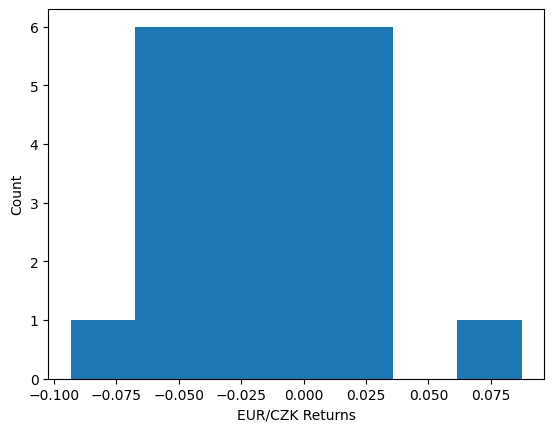

In [17]:
# Create histogram of EUR/CZK Returns
plt.hist(eur_czk["Log_return"], bins=7)
plt.xlabel("EUR/CZK Returns")
plt.ylabel("Count")
#plt.savefig("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Visualizations/Exchange rate/EUR_hist.pdf", format="pdf", bbox_inches="tight")
plt.show

### **USD/CZK**

In [18]:
# Data Load
usd_czk = pd.read_csv("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/exchange_rates/USD_CZK_old.csv")

In [19]:
# Transfer column Date to have date format and restrict the data to display only Czech koruna
usd_czk['Date'] = pd.to_datetime(usd_czk['Date'])
usd_czk = usd_czk[usd_czk['Date'] >= '1993-01-01']

# Add "Year" column
usd_czk['Year'] = pd.DatetimeIndex(usd_czk['Date']).year

In [20]:
# Data in ascending order by year
usd_czk = usd_czk.sort_values(by="Date").reset_index().drop("index", axis=1)

In [23]:
# ensure promer types
usd_czk['CZK= (BID)'] = pd.to_numeric(usd_czk['CZK= (BID)'], errors='coerce')

In [24]:
# Create year-to-year log return 
usd_czk["Log_return"] = np.nan
for i in range(1,len(usd_czk)):
    usd_czk.loc[i, "Log_return"] = np.round(np.log(usd_czk.loc[i, "CZK= (BID)"]/usd_czk.loc[i-1, "CZK= (BID)"]), 4)

In [25]:
# Check for Outliers
# Calculate mean, std
usd_std = np.std(usd_czk["Log_return"])
usd_mean = np.mean(usd_czk["Log_return"])

# Calculate Z-Score
usd_czk["Z-Score"] = np.nan
for i in range(len(usd_czk)):
    usd_czk.loc[i, "Z-Score"] = ((usd_czk.loc[i, "Log_return"] - usd_mean) / usd_std)

# Print out Outliers
usd_czk[np.abs(usd_czk["Z-Score"])>3] # Empty hence no outliers

,Date,CZK= (BID),Year,Log_return,Z-Score


In [26]:
# Calculate mean and standard deviation of EUR/CZK Returns
USD_mean = np.mean(usd_czk["Log_return"])
USD_var = np.var(usd_czk["Log_return"])
print(f"The CZK/USD has the average of {np.round(USD_mean,4)} and the variance of {np.round(USD_var,4)}")

The CZK/USD has the average of -0.007 and the variance of 0.0105


In [27]:
# Save mean and variance
#params_to_json("USD", np.round(USD_mean,4), np.round(USD_var,4))

In [28]:
# Check for max and min return
usd_czk[usd_czk["Log_return"] == np.max((usd_czk["Log_return"]))], usd_czk[usd_czk["Log_return"] == np.min(usd_czk["Log_return"])]

(        Date  CZK= (BID)  Year  Log_return   Z-Score
 4 1997-01-02      34.657  1997      0.2418  2.426138,
          Date  CZK= (BID)  Year  Log_return   Z-Score
 24 2017-01-02      21.278  2017     -0.1868 -1.753084)

In [ ]:
# Export back to Excel
#usd_czk.to_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/exchange_rates/USD_CZK.xlsx")

<function matplotlib.pyplot.show(close=None, block=None)>

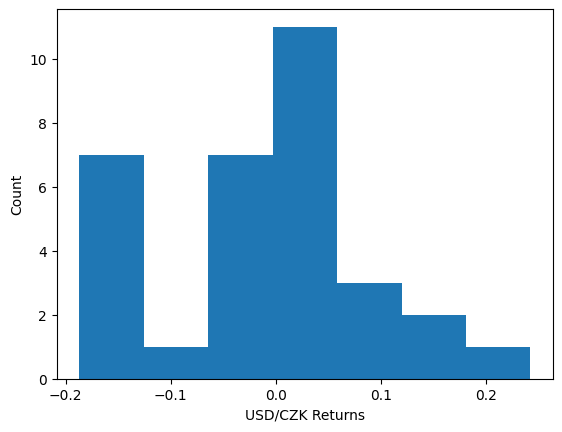

In [29]:
# Create histogram of EUR/CZK Returns
plt.hist(usd_czk["Log_return"], bins=7)
plt.xlabel("USD/CZK Returns")
plt.ylabel("Count")
#plt.savefig("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Visualizations/Exchange rate/USD_hist.pdf", format="pdf", bbox_inches="tight")
plt.show